In [97]:
import yfinance as yf  # load the library, nickname "yf"

# download daily SPY data since 2010 into a pandas table (DataFrame)
# auto_adjust=True corrects prices for dividends and splits,
# so a dividend day doesn't look like a fake price drop
spy = yf.download("SPY", start="2010-01-01", auto_adjust=True)

print(spy.shape)   # (number of rows, number of columns)
print(spy.head())  # first 5 rows

[*********************100%***********************]  1 of 1 completed

(4237, 5)
Price           Close       High        Low       Open     Volume
Ticker            SPY        SPY        SPY        SPY        SPY
Date                                                             
2010-01-04  84.368980  84.413646  83.014074  83.654305  118944600
2010-01-05  84.592316  84.629541  84.011642  84.316871  111579900
2010-01-06  84.651886  84.860332  84.443440  84.510438  116074400
2010-01-07  85.009209  85.113432  84.257309  84.495534  131091100
2010-01-08  85.292107  85.329332  84.614656  84.785878  126402800


In [98]:
# keep only the first header level (Close, High, ...) and drop "SPY"
spy.columns = spy.columns.droplevel(1)

print(spy.columns.tolist())  # list of column names
print(spy.isna().sum())      # missing values per column
print(spy.tail(3))           # last 3 rows

['Close', 'High', 'Low', 'Open', 'Volume']
Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64
Price            Close        High         Low        Open     Volume
Date                                                                 
2026-11-03  754.349976  757.070007  752.390015  752.729980   32891600
2026-11-04  766.809998  775.640015  762.640015  762.989990   62126400
2026-11-05  733.000000  765.969971  732.710022  765.469971  125340600


In [99]:
print(spy.columns.tolist())  # what are the column names right now?

['Close', 'High', 'Low', 'Open', 'Volume']


In [100]:
print(spy.isna().sum())  # for each column: how many empty cells (isna = "is missing?")
print(spy.tail(3))       # last 3 rows: the most recent trading days
print(spy.index.is_monotonic_increasing)  # True if the dates are in order, oldest to newest

Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64
Price            Close        High         Low        Open     Volume
Date                                                                 
2026-11-03  754.349976  757.070007  752.390015  752.729980   32891600
2026-11-04  766.809998  775.640015  762.640015  762.989990   62126400
2026-11-05  733.000000  765.969971  732.710022  765.469971  125340600
True


In [101]:
import os  # tools to work with folders

os.makedirs("data", exist_ok=True)  # create the "data" folder if it doesn't exist yet
spy.to_csv("data/spy.csv")          # save the table as a CSV text file
print(os.path.getsize("data/spy.csv"), "bytes saved")

401241 bytes saved


In [102]:
import pandas as pd  # table library, nickname "pd"

# load the saved CSV; index_col makes "Date" the row labels,
# parse_dates turns the text into real dates
spy = pd.read_csv("data/spy.csv", index_col="Date", parse_dates=True)

# daily return = (today's close - yesterday's close) / yesterday's close
spy["ret"] = spy["Close"].pct_change()

print(spy[["Close", "ret"]].head())

                Close       ret
Date                           
2010-01-04  84.368980       NaN
2010-01-05  84.592316  0.002647
2010-01-06  84.651886  0.000704
2010-01-07  85.009209  0.004221
2010-01-08  85.292107  0.003328


In [103]:
daily = [0.01, -0.01, 0.01, -0.01]   # a calm stock: moves 1% each day
wild  = [0.05, -0.05, 0.05, -0.05]   # a wild stock: moves 5% each day

# both average 0, but the spread is very different
print(pd.Series(daily).std())  # about 0.0115
print(pd.Series(wild).std())   # about 0.0577 -> 5x more volatile

0.011547005383792516
0.05773502691896258


In [104]:
print(spy["ret"].mean())  # the average daily return
print(spy["ret"].std())   # the daily volatility (NaN in row 1 is skipped automatically)

0.0005683678317021757
0.010744332216910677


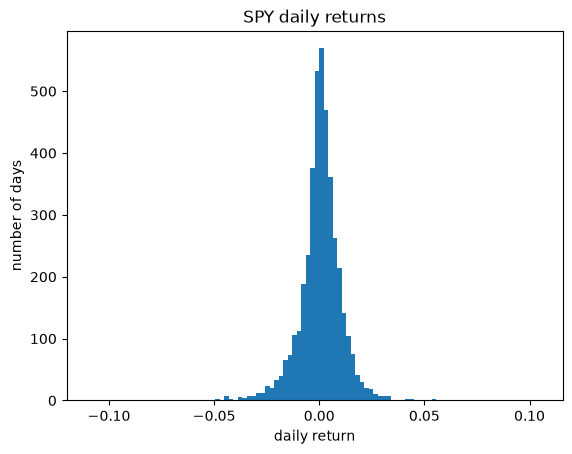

In [105]:
import matplotlib.pyplot as plt  # plotting library, nickname "plt"

# histogram: how many days had each return size
# bins=100 splits the range into 100 bars; dropna() removes the NaN in row 1
plt.hist(spy["ret"].dropna(), bins=100)
plt.title("SPY daily returns")
plt.xlabel("daily return")
plt.ylabel("number of days")
plt.show()  # draw it

In [106]:
# the 5 worst days (most negative returns), from the smallest value up
print(spy["ret"].nsmallest(5))

# the 5 best days
print(spy["ret"].nlargest(5))

Date
2020-03-16   -0.109424
2020-03-12   -0.095677
2020-03-09   -0.078094
2011-08-08   -0.065124
2025-04-04   -0.058543
Name: ret, dtype: float64
Date
2025-04-09    0.105020
2020-03-24    0.090603
2020-03-13    0.085486
2020-04-06    0.067166
2020-03-26    0.058390
Name: ret, dtype: float64


In [107]:
# a calm stretch followed by a stormy one (made-up daily returns)
returns = [0.001, -0.002, 0.001, 0.002, -0.001,   # calm days
           0.03, -0.04, 0.05, -0.03, 0.04]        # stormy days

import pandas as pd
r = pd.Series(returns)

# std of each 5-day window: small, then big -> volatility comes in clumps
print(r[:5].std())   # about 0.0016
print(r[5:].std())   # about 0.0422

0.0016431676725154984
0.04183300132670378


<Axes: title={'center': 'SPY 21-day rolling volatility'}, xlabel='Date'>

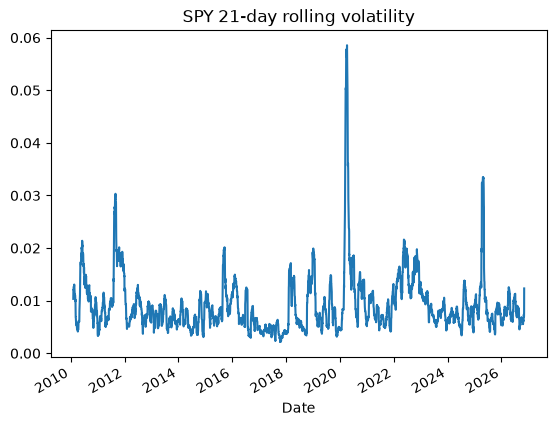

In [108]:
# rolling(21) = for each day, look at that day and the previous 20 trading days
# (about one month) and take the std of those returns
spy["vol_21"] = spy["ret"].rolling(21).std()

spy["vol_21"].plot(title="SPY 21-day rolling volatility")  # draw a line chart

In [109]:

# create the three rolling volatilities (each is a new column)
spy["vol_5"] = spy["ret"].rolling(5).std()      # about one week
spy["vol_21"] = spy["ret"].rolling(21).std()    # about one month
spy["vol_126"] = spy["ret"].rolling(126).std()  # about six months
print(spy.columns.tolist())

['Close', 'High', 'Low', 'Open', 'Volume', 'ret', 'vol_21', 'vol_5', 'vol_126']


In [110]:
spy[["vol_5", "vol_21", "vol_126"]].groupby(spy.index.year).mean()

,vol_5,vol_21,vol_126
Date,,,
2010,0.009952,0.010805,0.012637
2011,0.012294,0.012731,0.011399
2012,0.007377,0.007971,0.010797
2013,0.006414,0.006941,0.007338
2014,0.006138,0.006559,0.006596
2015,0.008641,0.009169,0.008893
2016,0.007077,0.007804,0.009256
2017,0.003915,0.004237,0.004745
2018,0.008717,0.008997,0.008335


In [111]:
import numpy as np  # numeric library, nickname "np"

daily_vol = 0.0165           # 2020's daily volatility (1.65%)
annual_vol = daily_vol * np.sqrt(252)   # sqrt(252) is about 15.87
print(annual_vol)            # about 0.262 -> 26.2% per year

0.2619293797953945


In [112]:
import numpy as np
print(spy["ret"].std() * np.sqrt(252))   # the whole-period annualized volatility

0.17056098629642968


In [113]:
import pandas as pd  # pandas para la tabla

# tabla de juguete: 6 días con un "valor" cada uno
df = pd.DataFrame({"valor": [10, 20, 30, 40, 50, 60]})

# shift(-2): negativo = jala el valor de 2 filas DESPUÉS hacia la fila actual
df["futuro_2"] = df["valor"].shift(-2)

# shift(2): positivo = trae el valor de 2 filas ANTES (pasado)
df["pasado_2"] = df["valor"].shift(2)

print(df)  # las filas sin dato quedan como NaN (en las orillas)

   valor  futuro_2  pasado_2
0     10      30.0       NaN
1     20      40.0       NaN
2     30      50.0      10.0
3     40      60.0      20.0
4     50       NaN      30.0
5     60       NaN      40.0


In [114]:
# nueva columna = std de 5 días de ret, movida ___ filas hacia el futuro, anualizada
spy["target"] = spy["ret"].rolling(5).std().shift(-5) * np.sqrt(252)

In [115]:
print(spy["target"].tail(8))  # últimas 8 filas del target
print(spy["target"].isna().sum())  # cuántos NaN hay en total

Date
2026-10-27    0.135962
2026-10-28    0.198321
2026-10-29    0.365408
2026-10-30         NaN
2026-11-02         NaN
2026-11-03         NaN
2026-11-04         NaN
2026-11-05         NaN
Name: target, dtype: float64
5


In [116]:
print(spy["ret"].std() * np.sqrt(252))   # volatilidad anualizada de SPY
print(spy["target"].isna().sum())        # NaN del target

0.17056098629642968
5


In [117]:
# rv_5: volatilidad de los últimos 5 días, anualizada
spy["rv_5"] = spy["ret"].rolling(5).std() * np.sqrt(252)

# rv_21: volatilidad de los últimos 21 días, anualizada
spy["rv_21"] = spy["ret"].rolling(21).std() * np.sqrt(252)

In [118]:
print(spy[["rv_5", "rv_21", "target"]].tail(8))        # últimas 8 filas
print(spy[["rv_5", "rv_21"]].isna().sum())             # cuántos NaN tiene cada una

                rv_5     rv_21    target
Date                                    
2026-10-27  0.131882  0.097370  0.135962
2026-10-28  0.128072  0.097647  0.198321
2026-10-29  0.088924  0.098422  0.365408
2026-10-30  0.162054  0.116592       NaN
2026-11-02  0.145348  0.113813       NaN
2026-11-03  0.135962  0.111280       NaN
2026-11-04  0.198321  0.125358       NaN
2026-11-05  0.365408  0.195784       NaN
rv_5      5
rv_21    21
dtype: int64


In [119]:
# rv_1: el movimiento de hoy, anualizado. rolling(1).std() no sirve (una std necesita 2+ valores),
# así que usamos el valor absoluto del retorno: abs() quita el signo (-2% y +2% mueven igual)
spy["rv_1"] = spy["ret"].abs() * np.sqrt(252)

# ret_5: retorno de los últimos 5 días (cuánto cambió el precio en una semana)
spy["ret_5"] = spy["Close"].pct_change(5)

In [120]:
features = ["rv_1", "rv_5", "rv_21", "ret_5"]       # lista con los nombres de las 4 features
print(spy[features + ["target"]].tail(6))           # últimas 6 filas: 4 features + target
print(spy[features + ["target"]].isna().sum())      # NaN de cada columna

                rv_1      rv_5     rv_21     ret_5    target
Date                                                        
2026-10-29  0.060636  0.088924  0.098422  0.007068  0.365408
2026-10-30  0.281440  0.162054  0.116592 -0.005592       NaN
2026-11-02  0.076041  0.145348  0.113813 -0.017338       NaN
2026-11-03  0.047491  0.135962  0.111280 -0.019892       NaN
2026-11-04  0.262208  0.198321  0.125358 -0.007121       NaN
2026-11-05  0.699935  0.365408  0.195784 -0.047260       NaN
rv_1       1
rv_5       5
rv_21     21
ret_5      5
target     5
dtype: int64


In [123]:
datos = spy[["rv_5", "target"]].dropna()              # filas con predicción y respuesta
error_abs = (datos["target"] - datos["rv_5"]).abs()   # distancia de cada predicción al valor real
mae_baseline = error_abs.mean()                        # ¿qué método saca el promedio?
print(mae_baseline)

0.06271472949024152


In [124]:
datos2 = spy[["rv_21", "target"]].dropna()                # ahora la predicción es rv_21
error_abs2 = (datos2["target"] - datos2["rv_21"]).abs()   # distancia al valor real
print(error_abs2.mean())                                  # MAE del baseline 2

0.06065004165498229


In [125]:
features = ["rv_1", "rv_5", "rv_21"]          # las 3 features del modelo HAR
datos = spy[features + ["target"]].dropna()    # solo filas completas
X = datos[features]                            # tabla de pistas
y = datos["target"]                            # la respuesta correcta

X_train = X.loc[:"2022-12-31"]                 # pasado: hasta fines de 2022
y_train = y.loc[:"2022-12-31"]
X_test  = X.loc["2023-01-09":]                        # futuro: desde esta fecha (deja un hueco de ~1 semana)
y_test  = y.loc["2023-01-09":]

print(len(X_train), len(X_test))               # cuántas filas hay en cada parte

3251 956


In [126]:
from sklearn.linear_model import LinearRegression   # el modelo de regresión lineal

modelo = LinearRegression()          # crea el modelo vacío (aún no sabe nada)
modelo.fit(X_train, y_train)         # aprende SOLO con el pasado (entrenamiento)

print(modelo.coef_)                  # los pesos a, b, c (uno por feature: rv_1, rv_5, rv_21)
print(modelo.intercept_)             # el número d (punto de partida)

[0.09451929 0.37279916 0.29004163]
0.03338706988392054


In [129]:
from sklearn.metrics import mean_absolute_error     # función que calcula el MAE por nosotros

pred_test = modelo.predict(X_test)                      # ¿cuál de los dos verbos: fit o predict?
mae_modelo = mean_absolute_error(y_test, pred_test) # MAE: respuestas reales vs. predicciones
print(mae_modelo)

# para comparar justo, el baseline rv_21 en las MISMAS filas de prueba:
mae_base = mean_absolute_error(y_test, X_test["rv_21"])  # ¿qué columna usa el baseline?
print(mae_base)

0.04786414300523872
0.05344252976767469


In [130]:
from sklearn.ensemble import RandomForestRegressor     # el bosque de árboles

bosque = RandomForestRegressor(
    n_estimators=200,        # cantidad de árboles del comité
    min_samples_leaf=20,     # cada hoja debe tener al menos 20 filas (evita memorizar)
    random_state=42,         # semilla: así el resultado se repite igual
)
bosque.fit(X_train, y_train)                       # ¿fit o predict? aprende con el pasado

pred_rf = bosque.predict(X_test)                       # ¿fit o predict? adivina en la prueba
print(mean_absolute_error(y_test, pred_rf))        # MAE del bosque

0.049883410755051656


In [131]:
from sklearn.model_selection import TimeSeriesSplit

# 5 exams; gap=5 skips 5 rows between train and test (same reason as before: overlapping target windows)
tscv = TimeSeriesSplit(n_splits=5, gap=5)

for i, (train_idx, test_idx) in enumerate(tscv.split(X)):
    # X.index holds the dates; train_idx / test_idx are row positions
    print(i, "train:", X.index[train_idx[0]].date(), "->", X.index[train_idx[-1]].date(),
          "| test:", X.index[test_idx[0]].date(), "->", X.index[test_idx[-1]].date())

0 train: 2010-02-03 -> 2012-11-13 | test: 2012-11-21 -> 2015-09-03
1 train: 2010-02-03 -> 2015-08-27 | test: 2015-09-04 -> 2018-06-18
2 train: 2010-02-03 -> 2018-06-11 | test: 2018-06-19 -> 2021-03-31
3 train: 2010-02-03 -> 2021-03-24 | test: 2021-04-01 -> 2024-01-12
4 train: 2010-02-03 -> 2024-01-05 | test: 2024-01-16 -> 2026-10-29


In [132]:
resultados = []  # one row of MAEs per exam

for i, (train_idx, test_idx) in enumerate(tscv.split(X)):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_te, y_te = X.iloc[test_idx], y.iloc[test_idx]

    # baseline: the "prediction" is just rv_21
    mae_base = (y_te - X_te["rv_21"]).abs().mean()

    # HAR: learn from THIS exam's train, predict THIS exam's test
    modelo = LinearRegression().fit(X_tr, y_tr)
    mae_har = (y_te - modelo.predict(X_te)).abs().mean()

    # random forest: same idea
    bosque = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=42).fit(X_tr, y_tr)
    mae_rf = (y_te - bosque.predict(X_te)).abs().mean()

    resultados.append([i, mae_base, mae_har, mae_rf])
    print(i, round(mae_base, 4), round(mae_har, 4), round(mae_rf, 4))

0 0.0525 0.0485 0.0466
1 0.0504 0.0454 0.0526
2 0.0857 0.0693 0.0779
3 0.0535 0.0529 0.0519
4 0.0598 0.0522 0.0532


In [133]:
import pandas as pd
# turn the list of rows into a table with named columns, then average each column
tabla = pd.DataFrame(resultados, columns=["examen", "base", "har", "rf"])
print(tabla[["base", "har", "rf"]].mean())

base    0.060386
har     0.053665
rf      0.056443
dtype: float64
